# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 - Import libraries

In [1]:
import re
from collections import Counter
from pathlib import Path

import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)


## Step 2 - Load the dataset

In [2]:
dataset_path = Path("Lab_11_QnA_Dataset.csv")
if not dataset_path.exists():
    dataset_path = Path("Lab11") / dataset_path

df = pd.read_csv(dataset_path).reset_index(drop=True)
print("Questions:", len(df))
print("Answer groups:", df["answer_id"].nunique())
df.head()


Questions: 168
Answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 - Preprocess the questions

Lowercase and tokenize each question, map words to IDs, and pad sequences with zeros.


In [3]:
def tokenize_question(text):
    return re.findall(r"[a-z0-9]+", text.lower())

question_tokens = df["question"].map(tokenize_question).tolist()
word_counts = Counter(word for tokens in question_tokens for word in tokens)
word_index = {word: i + 1 for i, (word, _) in enumerate(word_counts.most_common())}
max_len = max(map(len, question_tokens))

sequences = [[word_index[word] for word in tokens] for tokens in question_tokens]
X = torch.tensor(
    [seq + [0] * (max_len - len(seq)) for seq in sequences], dtype=torch.long
)
y = torch.tensor(df["answer_id"].to_numpy(), dtype=torch.long)

print("Vocabulary size:", len(word_index))
print("Padded question shape:", tuple(X.shape))


Vocabulary size: 225
Padded question shape: (168, 11)


## Step 4 - Build an RNN with attention

The RNN processes each question separately. Attention ignores padding and weights the real words.


In [4]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(word_index) + 1, 16, padding_idx=0)
        self.rnn = nn.RNN(16, 32, batch_first=True)
        self.att = nn.Linear(32, 1, bias=False)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        outputs, _ = self.rnn(self.emb(x))
        scores = self.att(outputs).squeeze(-1)
        scores = scores.masked_fill(x == 0, -1e9)
        weights = torch.softmax(scores, dim=1)
        context = (outputs * weights.unsqueeze(-1)).sum(dim=1)
        return self.fc(context), weights

model = RNN()


## Step 5 — Train the model
The model learns which answer belongs to each question.

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(150):
    model.train()
    optimizer.zero_grad()
    logits, _ = model(X)
    loss = nn.functional.cross_entropy(logits, y)
    loss.backward()
    optimizer.step()

    if (epoch + 1) % 25 == 0:
        with torch.no_grad():
            accuracy = (model(X)[0].argmax(dim=1) == y).float().mean().item()
        print(f"Epoch {epoch + 1}/150 - Loss: {loss.item():.3f} - Accuracy: {accuracy:.1%}")


Epoch 25/150 - Loss: 0.794 - Accuracy: 78.6%
Epoch 50/150 - Loss: 0.078 - Accuracy: 97.6%


Epoch 75/150 - Loss: 0.024 - Accuracy: 98.8%
Epoch 100/150 - Loss: 0.014 - Accuracy: 99.4%


Epoch 125/150 - Loss: 0.012 - Accuracy: 98.8%
Epoch 150/150 - Loss: 0.011 - Accuracy: 98.8%


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

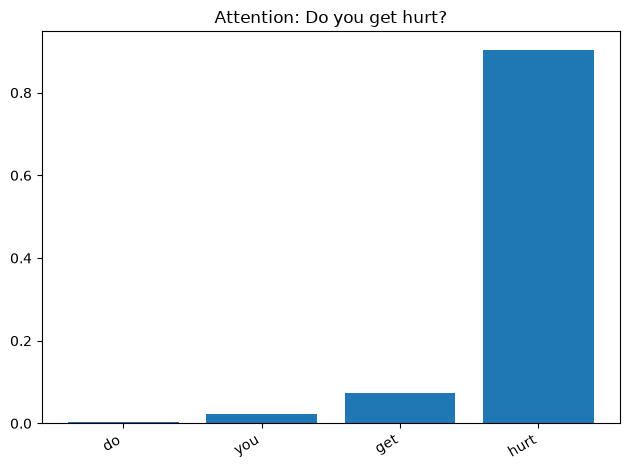

In [6]:
question = df.loc[0, "question"]
tokens = tokenize_question(question)

model.eval()
with torch.no_grad():
    _, weights = model(X[0:1])

plt.bar(tokens, weights[0, :len(tokens)].tolist())
plt.title("Attention: " + question)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

Do you get hurt? -> highest attention: hurt (0.903); predicted answer ID: 0
Who programmed you? -> highest attention: programmed (0.983); predicted answer ID: 3
Do you eat cake? -> highest attention: cake (0.750); predicted answer ID: 7


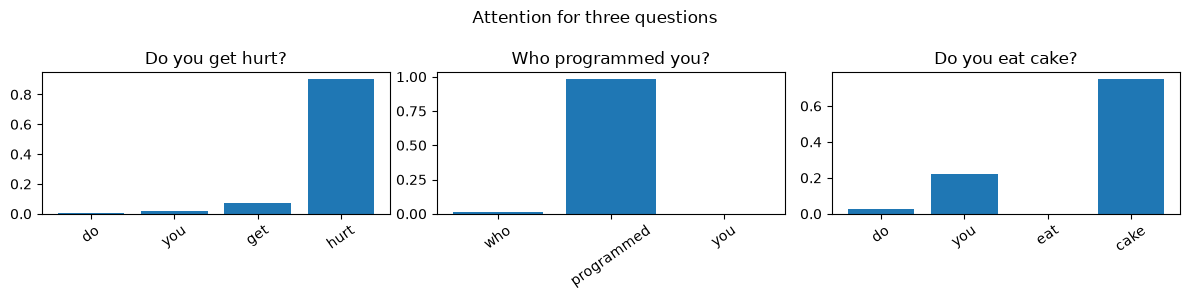

In [7]:
def show_attention(questions, title):
    model.eval()
    fig, axes = plt.subplots(1, len(questions), figsize=(4 * len(questions), 3), squeeze=False)

    for axis, question in zip(axes[0], questions):
        row = next(i for i, text in enumerate(df["question"])
                   if text.strip().lower() == question.strip().lower())
        tokens = tokenize_question(question)
        with torch.no_grad():
            logits, weights = model(X[row:row + 1])
        values = weights[0, :len(tokens)].tolist()
        best = max(range(len(tokens)), key=values.__getitem__)
        predicted_answer = int(logits.argmax(dim=1).item())

        axis.bar(tokens, values)
        axis.set_title(question)
        axis.tick_params(axis="x", rotation=35)
        print(f"{question} -> highest attention: {tokens[best]} ({values[best]:.3f}); predicted answer ID: {predicted_answer}")

    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

questions = ["Do you get hurt?", "Who programmed you?", "Do you eat cake?"]
show_attention(questions, "Attention for three questions")


**Observation:** Attention often highlights words that signal the topic, but it is a learned weighting rather than a complete explanation of the prediction.


Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Who programmed you? -> highest attention: programmed (0.983); predicted answer ID: 3
Who built you? -> highest attention: you (0.855); predicted answer ID: 3


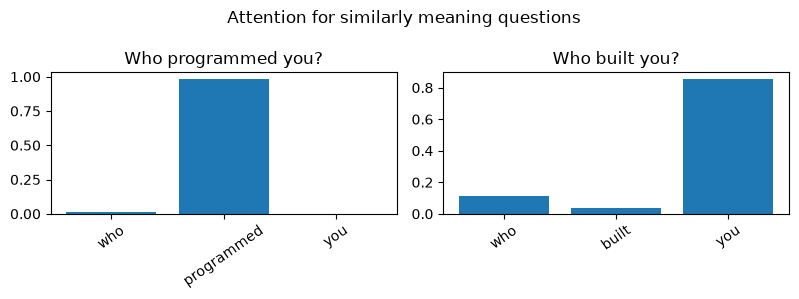

In [8]:
similar_questions = ["Who programmed you?", "Who built you?"]
show_attention(similar_questions, "Attention for similarly meaning questions")


**Observation:** The model focuses on `programmed` for one question and `you` for the other. Attention depends on each word's context, not just the overall meaning.
